In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
import statsmodels.api as sm

df = pd.read_csv("../../Day1/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
#1.1.1 Create a crosstab between the product category and the isBestSeller status.
cross_tab = pd.crosstab(df['category'], df['isBestSeller'])
cross_tab
print('cross_tab columns: ', cross_tab.columns.tolist())

cross_tab columns:  [False, True]


In [ ]:
# 1.1.2 Are there categories where being a best-seller is more prevalent?
cross_tab_sorted = cross_tab.sort_values(by = True, ascending = False)
cross_tab_sorted = cross_tab_sorted.rename(columns = {False : 'false', True : 'true'})
cross_tab_sorted['true_is_prevalent'] = (cross_tab_sorted['true'] > cross_tab_sorted['false'])
cross_tab_sorted[cross_tab_sorted['true'] > cross_tab_sorted['false']]

# 1.1.2 ANSWER: no categories with beign best_seller is prevalent

In [ ]:
# 1.2.1 Conduct a Chi-square test to determine if the best-seller distribution
# is independent of the product category.
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(cross_tab)

chi2_statistic, chi2_p_value, expected_freq


# Answer :1.2.1
chi2_p_value = 0.0 (<0.05) suggesting that our assumption is more likely to not happen. Meaning the best-seller distribution is related to the product category

In [3]:
#1.2.2 Compute Cramér's V to understand the strength of association between best-seller status and category.

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(cross_tab, method="cramer")

0.1222829439760564

In [ ]:
cross_tab

In [ ]:
# 1.3.1 Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
cross_tab_topn = cross_tab.nlargest(10, False)
cross_tab_topn.plot(kind = 'bar', stacked = True)
plt.xlabel('Product Category')
plt.title('Relationship between product cat and best seller status')
plt.show

In [4]:
# Part 2:
# 2.1.0 Preliminary Step: Remove outliers in product prices.
#Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers

#calculate quartiales and IQR
IQR = df.price.quantile(0.75) - df.price.quantile(0.25)
Q1 = df.price.quantile(0.25)
Q3 = df.price.quantile(0.75)
#calculate the limits
print("IQR = ", IQR )
print("Q1 = ",Q1 )
print("Q3 = ", Q3)
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print(lower_limit, upper_limit)
#remove the outliers:
df1 = df.loc[df.price < upper_limit, :]
#df1.shape
df1.head()

IQR =  36.0
Q1 =  9.99
Q3 =  45.99
-44.01 99.99000000000001


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
# 2.1.1  Use a violin plot to visualize the distribution of price across different product categories. 
#Filter out the top 20 categories based on count for better visualization.

#filter the top categories
top_20 = df1.category.value_counts().nlargest(20).index
#condition = 
df_cat = df1[df1.category.isin(top_20)]
sns.violinplot(data = df_cat, x = 'category', y = 'price', palette="coolwarm", hue='category', legend = False)
plt.xlabel('Product Catergory')
plt.ylabel('Price')
plt.show()

In [5]:
## 2.1.2 Which product category tends to have the highest median price? Don't filter here by top categories.
## ANSWER: Desktop PCs  have the highest median=74.00
df1.groupby('category')['price'].median().sort_values(ascending = False)
    

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

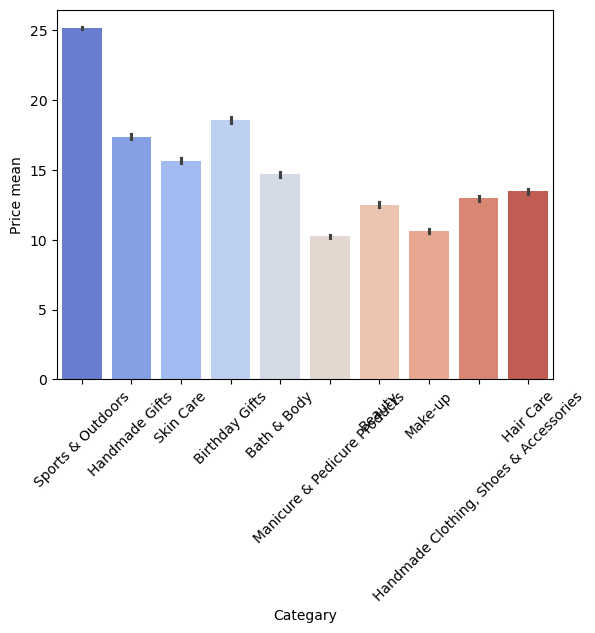

In [13]:
# 2.2.1 Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
#top 10 product categories
top10 = df1.category.value_counts().nlargest(10)

#filter the data frame
condition = df1.category.isin(top10.index)
df_top10 = df1[df1.category.isin(top10.index)]
df_top10.head()
sns.barplot(data = df_top10, x = 'category', y = 'price', palette="coolwarm", hue = 'category', legend = False)
plt.xlabel("Categary")
plt.ylabel("Price mean")
plt.xticks(rotation = 45)

plt.show()

In [18]:
# 2.2.2 Which product category commands the highest average price? Don't filter here by top categories.
max_mean = df1.groupby('category')['price'].mean().sort_values(ascending = False).nlargest(1)
max_mean
#ANSWER Motherboards    68.772432

category
Motherboards    68.772432
Name: price, dtype: float64

##  ANSWER  2.2.2: Motherboards    68.772432

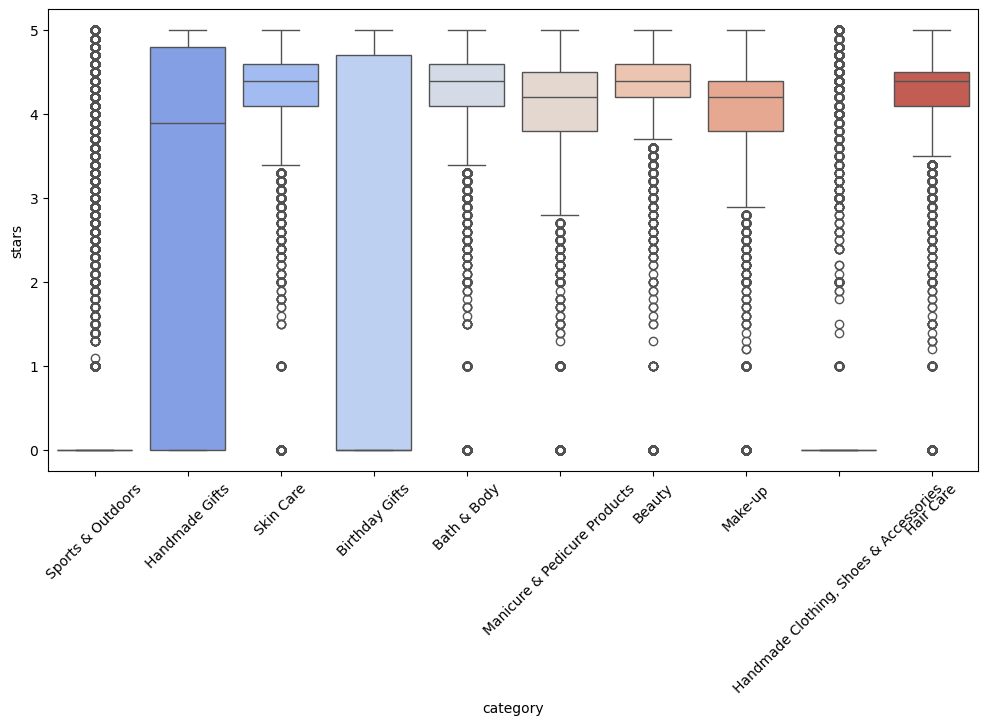

In [25]:
# 2.3.1 Visualize the distribution of product ratings based on their category using side-by-side box plots.
#Filter out the top 10 categories based on count for better visualization.
top10 = df1.category.value_counts().nlargest(10)
df_rating = df1[df1.category.isin(top10.index)]
plt.figure(figsize = (12, 6))
sns.boxplot(data = df_rating, x = 'category', y = 'stars', hue = 'category', palette = "coolwarm", legend = False)
plt.xticks(rotation = 45)
plt.show()

In [26]:
#2.3.2 Which category tends to receive the highest median rating from customers? 
#Don't filter here by top categories.
max_mean_rating = df1.groupby('category')['stars'].median().nlargest(1)
max_mean_rating


category
Computer Memory    4.7
Name: stars, dtype: float64

## Max median rating value per gategory is:
Computer Memory:4.7

In [28]:
 # 3.1.1 Calculate the correlation coefficient between price and stars.
correlation_sp = df1['price'].corr(df1['stars'], method = 'spearman')
correlation_pear = df1['price'].corr(df1['stars'], method = 'pearson')
correlation_sp, correlation_pear

                                

(np.float64(-0.06679697280768314), np.float64(-0.0776729987818137))

## # 3.1.1 ANSWER:
the correlations: Pearson = -0.0776, spearman= -0.0668, is very weak, meaning there is no correlation between the price and rating

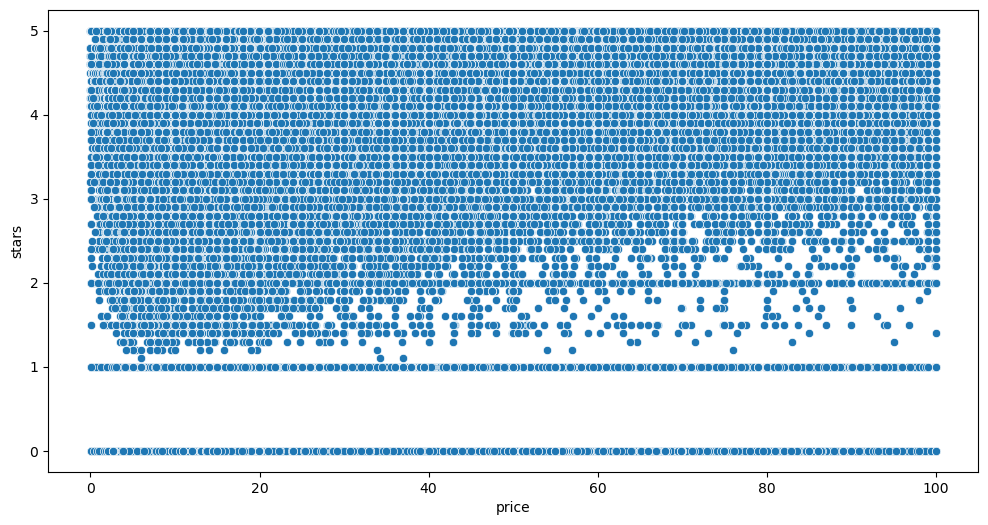

In [31]:
# 3.2.1 Use a scatter plot to visualize the relationship between product rating and price.
#What patterns can you observe?
plt.figure(figsize=(12,6))
sns.scatterplot(data = df1, x = 'price', y = 'stars')
plt.show()

## # 3.1.2 ANSWER:
No specific pattern

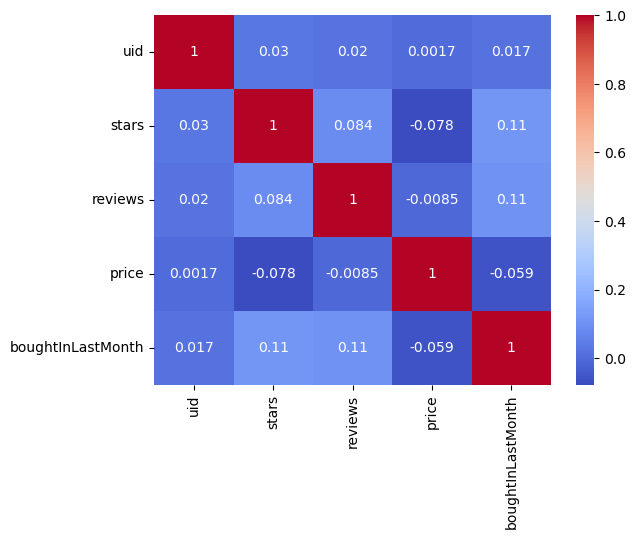

In [34]:
#3.2.2 Use a correlation heatmap to visualize correlations between all numerical variables.
df_numerical = df1.select_dtypes('number')
corr_matrix = df_numerical.corr()
corr_matrix
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

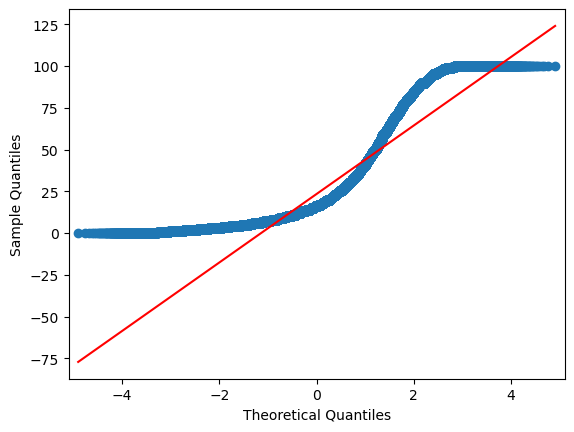

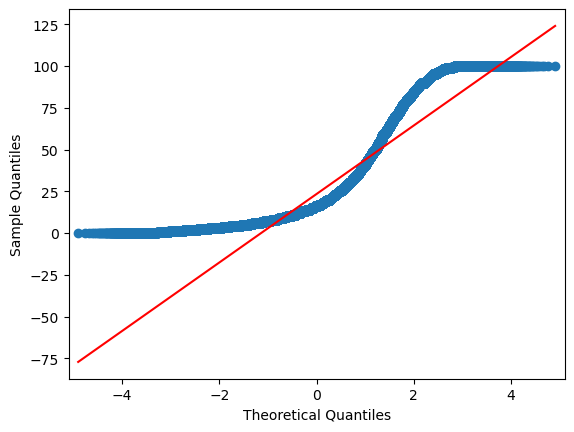

In [36]:
#3.2.3 Examine if product prices typically follow a normal distribution using a QQ plot.
sm.qqplot(df1['price'], line = 's')
